# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## Відповіді до 0.1.

**1. Чому модель помиляється при підрахунку літери «р» у слові «трансформер» (розділ 1.5):**

* **Причина помилки — субсловна токенізація (Byte-Level BPE):** LLM не бачить текст як послідовність окремих символів — перед подачею в нейромережу слово розбивається на багатосимвольні токени (наприклад, `тран`, `с`, `фор`, `мер` або `т`, `ранс`, `формер`). Оскільки на вхід подаються цілі ID токенів, модель не має прямого доступу до посимвольного складу слова і змушена «вгадувати» кількість літер із асоціацій у вагах.
* **Чому не допомагає режим міркувань (`think=True`):** під час спроби розкласти слово на літери (`Т, р, а, н, с, т, о, м, е, р` у виводі) модель генерує цю розбивку авторегресивно з власної пам'яті, де вже губить середину слова (`фор` перетворюється на `то`), тому в підсумку знаходить лише 2 літери «р» замість правильних 3 (т**р**ансфо**р**ме**р**).
* **Підтвердження:** якщо передати моделі слово вже розділеним на окремі токени-символи (наприклад, через дефіс `т-р-а-н-с-ф-о-р-м-е-р`), кожна літера потрапляє в окремий токен і модель рахує безпомилково.


In [ ]:

spaced_word = "-".join(word)
print("Запит із посимвольним розділенням:")
print(chat(INSTRUCT_MODEL, f"Порахуй, скільки разів літера «р» трапляється в записі: {spaced_word}", think=False)["message"]["content"])

Запит із посимвольним розділенням:
Вираз: **т-р-а-н-с-ф-о-р-м-е-р**

Ми потрібно визначити, скільки разів літера **«р»** трапляється в цьому рядку.

Розглянемо кожну літеру:

1. **т** — не «р»  
2. **р** — **1 раз**  
3. **а** — не «р»  
4. **н** — не «р»  
5. **с** — не «р»  
6. **ф** — не «р»  
7. **о** — не «р»  
8. **р** — **2 раз**  
9. **м** — не «р»  
10. **е** — не «р»  
11. **р** — **3 раз**

**Відповідь: 3 рази.**


**2. Як у розділі 2.4 демо змінюються перплексія й метрики перекладу від fp16 до int2? Між якими варіантами стрибок найбільший?:**

* **Від `fp16` до `int8` та `int4` — якість майже не падає:**
  * **Перплексія:** залишається на одному рівні при переході з `fp16` на `int8` (`2.67` для English і `2.40` для української) і лише незначно зростає на `int4` (до `2.81` і `2.76` відповідно).
  * **Метрики перекладу (`chrF` і `BLEU`):** зберігають високі значення без деградації (`chrF`: `55.22` → `58.25` → `55.34`; `BLEU`: `23.71` → `26.17` → `29.79` — незначні коливання вгору пояснюються іншим підбором синонімів у межах правильного перекладу).

* **При переході на `int2` — повний колапс моделі:**
  * **Перплексія** вибухоподібно зростає до катастрофічних значень: **`60091.86`** для English (зростання більш ніж у **21 000 разів** порівняно з `int4`) та **`34451480.00`** для української мови (понад **12 млн разів**).
  * **Метрики перекладу** падають майже до нуля: **`chrF`** обвалюється з `55.34` до **`0.19`**, а **`BLEU`** — з `29.79` до **`0.12`** (модель починає генерувати незв'язний набір символів замість слів).

* **Де стрибок найбільший:**
  * Найбільший (різкий, пороговий) стрибок відбувається **між `int4` та `int2`**. Якщо при стисненні з 16 до 4 біт сітка значень ваг ще зберігає структуру розподілу параметрів нейромережі, то при 2 бітах на вагу (лише 4 можливі дискретні значення на число) похибка квантизації руйнує внутрішні представлення моделі.

**3. Порівняння зростання перплексії для англійської й української мов:**

* **Ні, перплексія зростає нерівномірно — українська деградує значно сильніше:**
  * На `int4` відносно `fp16`: для англійської перплексія зросла на **+5.2%** (`2.67` → `2.81`), тоді як для української — на **+15.0%** (`2.40` → `2.76`).
  * На `int2` (повний колапс): для англійської показник злетів до **`60 091.86`** (у ~22 500 разів від `fp16`), а для української — до **`34 451 480.00`** (у ~14,35 млн разів від `fp16` — більш ніж у 570 разів вище за англійську).
* **Поірвняння зі слайдом «Де може просідати якість при квантизації»:**
  * Результати експерименту підтверджують тезу зі слайду: **«Першими ламаються математика й складні міркування, а також мови з нелатинською абеткою — зокрема й українська»**.
  * Кирилиця представлена в навчальному корпусі моделі меншою часткою даних і менш щільними патернами ваг, ніж англійська латиниця, тому при зменшенні бітності ваг похибка округлення руйнує мовні репрезентації української набагато швидше.

**4.Чи збігається ваш вибір у сліпому порівнянні (розділ 2.5 демо) з тим, що показали автоматичні метрики? Чи помітили ви різницю там, де метрики майже не змінилися, — або навпаки?**

* **Результати вибору:** паритет — **`fp16` краща: 1, `int4` краща: 1, однаково: 3** (`VOTES = {1: "A", 2: "=", 3: "=", 4: "A", 5: "="}`).
* **Збіг із метриками:** загальний баланс повністю відповідає результатам розділу 2.4, де `fp16` та `int4` показали майже однакові значення перплексії ). На англійських завданнях моделі ідентичні за якістю.

**5. Знайдіть у таблиці перекладів (розділ 2.4 демо) правильний переклад, який відрізняється від еталона словами. Як на нього реагують BLEU і chrF?**

* **Приклад із таблиці:**
  * **Оригінал:** *"It is going to rain tomorrow, so take an umbrella."*
  * **Еталон:** *"Завтра буде дощ, тож візьміть парасольку."*
  * **Переклад `int8`:** *"Завтра піде дощ, тому візьміть з собою парасольку."* (зміст передано точно, але використано синоніми «піде» замість «буде», «тому» замість «тож» та додано «з собою»; інший приклад — *"The meeting has been moved to Thursday at three o'clock."* → еталон *"Зустріч перенесли на четвер на третю годину."* проти `int8` *"Зустріч перенесли на четвер, о 15 годині."*).

* **Реакція метрик на такий переклад:**
  * **BLEU падає різко (сильно штрафує):** метрика рахує точні збіги цілих слів та n-грам слів (1–4 слова поспіль). Заміна «буде» → «піде», «тож» → «тому» або «на третю» → «о 15» руйнує біграми та триграми, через що BLEU знижується, попри правильний зміст.
  * **chrF реагує значно м'якше (більш стійка):** метрика порівнює перетин символьних n-грам (послідовностей літер), тому спільні корені слів («дощ», «візьміть», «парасольку», «четвер», «годин-») зберігають високий відсоток збігів навіть при інших словоформах або частковій заміні слів.

**6.У скільки разів зменшилася памʼять у таблиці розділу 2.4 демо і чому не рівно вдвічі, вчетверо й увосьмеро? Чи стала генерація швидшою?:**

* **У скільки разів зменшилася памʼять моделі (відносно `fp16` — `9.88 GB`):**
  * **`int8` (`6.25 GB`):** у **1.58 раза** (пік VRAM: `10.46` → `6.83 GB`, у **1.53 раза**).
  * **`int4` (`4.56 GB`):** у **2.17 раза** (пік VRAM: `10.46` → `5.14 GB`, у **2.04 раза**).
  * **`int2` (`3.64 GB`):** у **2.71 раза** (пік VRAM: `10.46` → `4.22 GB`, у **2.48 раза**).

* **Чому не рівно вдвічі, вчетверо й увосьмеро:**
  * **Неквантовані шари:** великі матриці ембедінгів (`embed_tokens`) та вихідна голова (`lm_head`) залишаються у форматі `fp16`/`bf16`, щоб не втратити якість словника, і займають фіксований обсяг памʼяті (~2–2.5 ГБ).
  * **Накладні витрати квантизації:** для кожної групи ваг (зазвичай 32–128 елементів) додатково зберігаються параметри масштабування (`scales`) та зміщення (`zero-points`) у вищій точності.
  * **Службові буфери в піку VRAM:** KV-кеш, проміжні активації та контекст CUDA мають однаковий розмір незалежно від бітності ваг.

* **Чи стала генерація швидшою:**
  * **Ні, швидкість навпаки впала в 2.6–5.3 раза:** з **`15.59 tokens/s`** на `fp16` до **`6.04 tokens/s`** на `int8`, **`2.96 tokens/s`** на `int4` та **`3.02 tokens/s`** на `int2`.
  * **Причина:** бібліотека `Quanto` (через `transformers`) при `batch_size=1` витрачає більше часу на програмну деквантизацію ваг «на льоту» перед множенням матриць, ніж економить на читанні стиснутих даних із VRAM (без спеціалізованих швидких CUDA-ядер на кшталт Marlin або llama.cpp).


**7. Поведінка Base-моделі у розділі 1.2 та отримання відповіді:**

* **Чому відповідає новими питаннями:** Base-модель пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент. Одиночний рядок `"Яка столиця Франції?"` без структурного контексту статистично найближчий до списку тестових або вікторинних запитань із тренувальних даних, тому модель продовжує патерн і генерує наступні питання.
* **Як змусити Base-модель дати відповідь:** потрібно задати явний патерн продовження тексту — у форматі **«Питання / Відповідь»** або як незакінчене твердження, яке природно завершується правильною відповіддю.


In [ ]:
prompt = (
    "Питання: Яка столиця України?\n"
    "Відповідь: Київ.\n\n"
    "Питання: Яка столиця Німеччини?\n"
    "Відповідь: Берлін.\n\n"
    "Питання: Яка столиця Франції?\n"
    "Відповідь:"
)
print(generate_raw(BASE_MODEL, prompt, max_tokens=15))

 Паризька.

Питання: Яка столиц


**8. Скільки токенів і часу забрали міркування в розділі 1.4 порівняно з відповіддю без міркувань? Чому модель міркує англійською, хоча питання українською?:**

* **Витрати токенів і часу:**
  * Без міркувань: згенеровано **252 токени** за **2.3 с**.
  * Із міркуваннями: згенеровано **566 токенів** (з яких 1459 символів припадає на внутрішній блок міркувань) за **5.6 с**.
  * Режим міркувань витратив на **314 токенів більше** (у **2.25 раза** більше токенів) та зайняв на **3.3 с більше часу** (у **2.43 раза** довше).

* **Чому модель міркує англійською мовою, хоча питання українською:**
  * **Перевага англомовних даних при RL-донавчанні (Reasoning SFT / GRPO):** ланцюжки міркувань (Chain-of-Thought) для логічних і математичних задач під час пост-тренування моделей сімейства Qwen переважно формувалися англійською мовою.
  * **Вища ефективність токенізації та точності:** англійські логічні зв'язки (`First`, `So`, `Wait`, `Therefore`) мають сильніші асоціації з покроковими обчисленнями у вагах моделі й займають менше токенів на слово, ніж кирилиця, тому модель перемикається на англійську для «внутрішнього монологу», а фінальну відповідь генерує мовою запиту користувача.

#### **9. Знайдіть задачу, на якій режим міркування дає правильну відповідь, а без нього модель помиляється. Наведіть промпт і обидві відповіді.**



In [34]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

In [35]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [36]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.18


#### Промт

In [37]:
compare_thinking(
    "Даша має 3 братів. У кожного з її братів є рівно 2 сестри. "
    "Скільки всього дітей у цій сім'ї?"
)

=== think=False | токенів: 356 | генерація: 3.0 с
--- відповідь:
Давайте розглянемо задачу логічно:

**Даша має 3 братів. У кожного з її братів є рівно 2 сестри. Скільки всього дітей у цій сім'ї?**

### Розуміння:
- Даша — дівчинка.
- Вона має **3 братів**. Це означає, що у сім'ї **4 дітей** (Даша + 3 брати).
- У кожного з братів є **2 сестри**. Це означає, що у сім'ї **2 сестри**, які не є Дашою (ось чому відповідь не є 4, а ще 2).

### Висновок:
- У сім'ї 4 дітей (Даша + 3 брати).
- У кожного брата є 2 сестри — це **2 дівчинки**.
- Тому **всього дітей** у сім'ї:  
  $$
  1 \text{ (Даша) } + 3 \text{ (брати) } + 2 \text{ (сестри) } = 6
  $$

### Відповідь:
$$
\boxed{6}
$$

=== think=True | токенів: 1989 | генерація: 17.7 с
--- міркування (6553 символів), початок:
Okay, let's try to figure out this problem. So, Dasha has 3 brothers. Each of her brothers has exactly 2 sisters. We need to find out how many children are in the family. Hmm, let's break it down step by step.

First, let's n





#### **10. У функціях `generate_raw` і `chat` (розділ 1.1) стоять temperature: 0 і seed: 1. Навіщо?:**

* **`temperature: 0`:** вимикає випадковість під час вибору наступного токена — модель обирає токен із найвищою ймовірністю (argmax), замість того щоб семплювати з розподілу.
* **`seed: 1` (фіксація генератора псевдовипадкових чисел):** забезпечує детермінованість та відтворюваність результатів на рівні бекенду (llama.cpp / Ollama), якщо виникають нічиї за ймовірностями або внутрішні стохастичні операції.

Разом вони забезпечують коректне й відтворюване порівняння режимів (**Base** проти **Instruct**, а також `think=False` проти `think=True`) на однакових промптах, щоб різниця у відповідях зумовлювалася виключно типом моделі чи режимом міркування, а не випадковим семплюванням.

**11. Чому в секції 2 використовуємо fp16, а не bf16? Що показує torch.cuda.get_device_capability() на T4 і як це з цим повʼязано?**

* **Що показує `torch.cuda.get_device_capability()` на T4:** `(7, 5)` (архітектура NVIDIA Turing, major-версія `7 < 8`).
* **Зв'язок із кодом і форматом `fp16`:**
  * Апаратна підтримка `bf16` на тензорних ядрах NVIDIA з'явилася лише з Compute Capability `8.0` (Ampere і новіші). На T4 (`7.5`) апаратно підтримується лише `fp16` (інакше PyTorch падає в повільну емуляцію через `fp32`).
  * Крім того, скомпільовані CUDA-ядра розпакування ваг у `quanto_cuda` вимагають архітектуру $\ge 8.0$ (`get_device_capability()[0] >= 8`). Через перевірку `if torch.cuda.get_device_capability()[0] < 8:` на T4 відбувається підміна (`monkey-patch`) виклику `quanto_cuda._lib.unpack` на чисту Python/PyTorch-реалізацію `unpack_weights`, що також пояснює низьку швидкість інференсу квантованих моделей у Colab.


**12. Скільки параметрів у моделі з розділу 2.1 і скільки памʼяті має займати її fp16-версія за формулою з лекції? Порівняйте з «памʼяттю моделі» в таблиці розділу 2.4.:**

* **Кількість параметрів:** у моделі `Qwen3-4B-Instruct-2507` зазначено **4B (4 мільярди)** параметрів (фактично за розміром файлів на диску ~8.04 ГБ модель містить близько **4.02B** параметрів).
* **Теоретичний обсяг памʼяті за формулою з лекції:**
  $$\text{Пам'ять (ГБ)} \approx N_{\text{параметрів (B)}} \times \frac{\text{біт на параметр}}{8} = 4 \times \frac{16}{8} = 4 \times 2 = \mathbf{8\text{ ГБ}}$$
* **Порівняння з таблицею розділу 2.4:**
  * У таблиці «памʼять моделі, GB» для `fp16` становить **`9.88 GB`** — це на **1.88 ГБ більше** за теоретичні ~8 ГБ (і на 1.84 ГБ більше за розмір чистих ваг 8.04 ГБ).
  * **Причина розбіжності:** показник `torch.cuda.memory_allocated()` у VRAM враховує не лише ваги моделі (`~8.04 ГБ`), а й зарезервований CUDA-контекст PyTorch (~0.5–1 ГБ), проміжні буфери обчислень, маски уваги та KV-кеш, виділені під час прогону текстів[cite: 29, 30].

**13. Перплексія, порівняння між мовами та тест на випадковому наборі слів (розділ 2.2):**

* **Що таке перплексія ($\text{PPL}$):** це метрика невизначеності мовної моделі під час передбачення послідовності токенів, математично визначена як експонента від середньої крос-ентропії (negative log-likelihood) на кожному токені:
  $$\text{PPL}(X) = \exp\left(-\frac{1}{N} \sum_{i=1}^{N} \log P(x_i \mid x_{<i})\right)$$
  Інтуїтивно вона показує ефективний розмір словника (кількість рівноймовірних варіантів), між якими модель у середньому «вагається» на кожному кроці: чим нижча перплексія, тим упевненіше й точніше модель передбачає наступний токен.

* **Чому перплексію не можна порівнювати між англійською та українською мовами:**
  * **Різна гранулярність токенізації (fertility):** BPE-токенізатори зазвичай мають значно більше цілих англійських слів у словнику (1 слово $\approx$ 1.1–1.3 токена), тоді як українські слова розбиваються на дрібніші субсловні фрагменти або окремі байти/літери (1 слово $\approx$ 2–3 токени).
  * **Штучне заниження перплексії на дрібних токенах:** коли слово розбите на кілька частин, передбачити другу чи третю частину вже розпочатого українського слова значно легше, ніж ціле наступне слово. Через це середня похибка на один токен у мові з дрібнішою токенізацією може бути нижчою, навіть якщо сама модель знає цю мову гірше.


**14. Чому «пік VRAM» у таблиці розділу 2.4 більший за «памʼять моделі»? Що ще, крім ваг, займає памʼять під час генерації?**

* **Різні моменти вимірювання:** «памʼять моделі» фіксується одразу після завантаження ваг на GPU (у стані спокою), а «пік VRAM» — це максимум виділеної памʼяті під час виконання генерації та обчислення перплексії (різниця в таблиці становить стабільні **+0.58 GB** для всіх варіантів).
* **Що ще займає VRAM під час інференсу, крім статичних ваг:**
  * **KV-кеш (Key-Value Cache):** збережені тензори ключів і значень механізму уваги для всіх токенів вхідного промпту та вже згенерованої відповіді, щоб не перераховувати їх на кожному кроці.
  * **Проміжні активації (Activations):** тимчасові тензори, які виникають під час проходження даних крізь шари трансформера (MLP, LayerNorm, Attention).
  * **Матриця логітів (`logits`) та масок уваги:** вихідний тензор імовірностей розміром `[batch_size, seq_len, vocab_size]` (для словника Qwen3 на ~152 тис. токенів це сотні мегабайтів на кожному кроці).
  * **Робочі буфери CUDA / деквантизації:** тимчасова памʼять бібліотек (`cuBLAS`, `PyTorch`) для матричного множення та розпакування квантованих ваг (`int8`/`int4`/`int2`) у `fp16` під час обчислень.

  **15. Скільки разів у сліпому порівнянні (розділ 2.5) ви обрали fp16, int4 чи «однаково»? Наскільки впевнено можна робити висновки з 5 порівнянь і скільки їх знадобилося б для надійного висновку?**

* **Кількість виборів у сліпому тесті:**
  * **`fp16` краща:** 1 раз.
  * **`int4` краща:** 1 раз.
  * **«Однаково»:** 3 рази.

* **Наскільки впевнено можна робити висновки з 5 порівнянь:**
  * **Впевненість вкрай низька (статистично незначуща вибірка).** При $N = 5$ (і лише 2 результатах без нічиєї) навіть один випадковий збій або обрив генерації через ліміт токенів змінює співвідношення перемог на 20–50%. Така вибірка підходить лише для швидкої візуальної перевірки, щоб переконатися, що модель не зламалася, але не доводить рівність або перевагу одного формату.

* **Скільки порівнянь потрібно для надійного висновку:**
  * Для фіксації помірної різниці в якості (наприклад, розриву в 10–15% за кількістю перемог / win-rate при рівні довіри 95% і потужності тесту 80%) зазвичай потрібно **від 100 до 300 парних порівнянь** на різноманітних промптах (код, логіка, переклад, українська та англійська мови).

**16. Як саме «ламається» модель у int2 (розділ 2.6)? Опишіть типові помилки у відповідях. Чи помітні їхні ознаки вже в int4?**

* **Типові помилки у відповідях `int2` (повний колапс генерації):**
  * **Зациклення (repetition loops):** модель застрягає на повторенні одного слова, складу або спецсимволу (`had had had...`, `bet bet bet...`, `htonhtonhton...`, нескінченні рядки зворотних слешів `\\\\\\\\` та крапок `......`).
  * **Втрата мови та змішування алфавітів:** замість українського тексту генерується незв'язний набір англійських уривків (`again`, `system`, `rest`, `Attachment`), випадкових символів (`°`, `\n`) та ієрогліфів (`航`, `八`).
  * **Повна втрата розуміння інструкцій:** модель не здатна дотримуватися контексту запиту й не генерує жодного осмисленого речення чи коректного токена завершення генерації (`EOS`).

* **Чи помітні їхні ознаки вже в `int4`:**
  * **Серйозного колапсу (зациклення, «сміття» або зміни мови) у `int4` ще немає** — структура речень, логіка та формат відповіді зберігаються.
  * **Проте з'являються ранні лексико-стилістичні огріхи в українській мові:** модель починає підбирати семантично неточні або неприродні слова та звороти.


In [ ]:
def perplexity(model, text):
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))

random_words = (
    "холодильник парасолька інтеграл кенгуру табуретка синхрофазотрон "
    "помідор галактика викрутка симфонія кактус пароплав олівець "
    "транзистор метелик екскаватор кавун бібліотека термометр динозавр"
)

ppl_coherent = perplexity(fp16_model, PPL_TEXT["Українська"])
ppl_random = perplexity(fp16_model, random_words)

print(f"Перплексія fp16 (осмислений український текст): {ppl_coherent:.2f}")
print(f"Перплексія fp16 (випадковий набір слів):         {ppl_random:.2f}")
print(f"Зростання невизначеності: у {ppl_random / ppl_coherent:.1f} раза")

del fp16_model
torch.cuda.empty_cache()

Перплексія fp16 (осмислений український текст): 2.40
Перплексія fp16 (випадковий набір слів):         16.61
Зростання невизначеності: у 6.9 раза


* **Пояснення результату на випадковому наборі слів:** у випадковому наборі слів відсутні граматичні, синтаксичні та семантичні зв'язки. На кожному кроці модель не може використати попередній контекст для звуження вибору й призначає наступному токену вкрай низьку ймовірність $P(x_i \mid x_{<i})$, через що крос-ентропія різко зростає, а перплексія стрибає з одиниць (типово ~5–12 на осмисленому тексті) до **сотень або тисяч** (тобто рівень «вагання» наближається до вгадування з великого набору непов'язаних слів).

**17. Порівняння результатів квантизації `Qwen/Qwen3-1.7B` та `Qwen3-4B`:**

| Метрика / Варіант | Qwen3-4B (`fp16` → `int8` → `int4` → `int2`) | Qwen3-1.7B (`fp16` → `int8` → `int4` → `int2`) |
| :--- | :---: | :---: |
| **Перплексія (English)** | `2.67` → `2.67` → `2.81` → `60 091.86` | `4.35` → `4.45` → `7.52` → `438 691.38` |
| **Перплексія (Українська)** | `2.40` → `2.40` → `2.76` → `34 451 480.00` | `3.10` → `3.11` → `5.60` → `5 951 889.50` |
| **chrF перекладу** | `55.22` → `58.25` → `55.34` → `0.19` | `48.74` → `47.44` → `29.01` → `0.24` |

* **Так, квантизація бʼє по меншій моделі (`1.7B`) значно сильніше (особливо на `int4`):**
  * **На `int8`:** обидві моделі майже не втрачають якості (`chrF` у `1.7B` знижується лише на `1.30` бала: `48.74` → `47.44`, перплексія стабільна).
  * **Критична різниця на `int4`:** якщо `4B` зберігає якість перекладу без втрат (`chrF` залишається на рівні `55.34`, а перплексія зростає лише на `+5%` для EN і `+15%` для UK), то у `1.7B` на `int4` вже настає різка деградація:
    * **Перплексія** зростає майже вдвічі: для English — на **+72.9%** (`4.35` → `7.52`), для української — на **+80.6%** (`3.10` → `5.60`).
    * **`chrF` перекладу** обвалюється на **19.73 бала** (`48.74` → `29.01`), а `BLEU` — з `23.83` до `4.30`.
  * **На `int2`:** обидві моделі зазнають повного колапсу генерації (`chrF` падає до `0.19–0.24`, перплексія злітає до сотень тисяч і мільйонів).
* **Висновок:** у меншій моделі (`1.7B`) менше надлишкових параметрів, тому вже 4-бітна квантизація суттєво ламає генерацію українських перекладів, тоді як для `4B` формат `int4` є практично безвтратним.

**18. Поясніть принцип параметру OLLAMA_NUM_PARALLEL в ollama з демо?**

* **Що робить параметр:** визначає максимальну кількість паралельних запитів (`slots`), які одна завантажена модель може обробляти одночасно (за замовчуванням у демо або в сервері Ollama зазвичай встановлюється `1` або автовизначається залежно від вільної памʼяті — 1–4 слоти).
* **Механізм роботи (Continuous Batching + виділення KV-кешу):**
  * Замість того, щоб ставити запити різних користувачів у чергу один за одним (`OLLAMA_NUM_PARALLEL=1`), Ollama розбиває виділений під модель KV-кеш на $N$ незалежних слотів (контекстів) і об'єднує обчислення активних запитів у спільні батчі на кожному кроці генерації токена.
* **Вплив на ресурси та швидкість:**
  * **VRAM:** споживання відеопамʼяті зростає, оскільки під кожен паралельний слот заздалегідь резервується власний буфер KV-кешу розміром `context_length` (фактичний контекст ділиться або множиться на `OLLAMA_NUM_PARALLEL`).
  * **Продуктивність:** загальна пропускна здатність сервера (сумарна кількість токенів/с для всіх користувачів) зростає, але швидкість генерації для кожного окремого запиту трохи знижується порівняно з одиночним виконанням.

**19. Чому майже всі сучасні моделі зберігаються у форматі BF16 (на основі слайду):**

* **Ширший діапазон значень і захист від переповнення (`inf` чи `0`):** у `BF16` під експоненту виділено **8 біт** (як у `FP32`), що дозволяє записувати числа до **$\sim 10^{38}$**, тоді як `FP16` має лише 5 біт експоненти й обмежується діапазоном **$\pm 65\,504$** (через що, наприклад, число `70 000` у `FP16` перетворюється на `inf`, а в `BF16` зберігається як `70 144` зі збереженням порядку величини).
* **Стійкість нейромереж до округлення, але критичність переповнень:** `BF16` поступається `FP16` у точності дробової частини через меншу мантису (7 біт проти 10 біт; наприклад, `1.001` округляється до `1.0`), проте нейромережі нормально витримують похибку в третьому знаку, тоді як поява `inf` чи `0` миттєво ламає обчислення та навчання — саме тому `BF16` є стандартом для LLM.

**20. Навіщо рантайми моделей підтримують протокол OpenAI і як це повʼязано з ChatGPT:**

* **Для чого рантайми (Ollama, vLLM, LM Studio, llama.cpp тощо) слідують протоколу OpenAI:**
  * **Фактичний стандарт індустрії (drop-in replacement):** уніфікований формат ендпоінтів (`/v1/chat/completions`, `/v1/models`, `/v1/embeddings`) та JSON-схеми запитів і відповідей дозволяє перемикатися між хмарними й локальними моделями без переписування коду програми — достатньо змінити лише `base_url` та назву моделі.
  * **Миттєва сумісність з усією екосистемою:** бібліотеки, фреймворки, IDE-плагіни та клієнтські застосунки (офіційні SDK OpenAI, LangChain, Open WebUI тощо) одразу працюють із локальним сервером «з коробки», без потреби писати окремі адаптери під кожен рушій інференсу.
  * **Уніфікація ролей та функцій:** протокол стандартизує передачу історії діалогу через ролі (`system`, `user`, `assistant`), потокову передачу токенів (streaming через SSE) та виклик інструментів (function/tool calling).

* **Як це повʼязано з ChatGPT:**
  * **Історичне першопрохідництво:** після виходу ChatGPT наприкінці 2022 року API OpenAI для чат-моделей (`Chat Completions`) першим набуло масового поширення серед розробників, завдяки чому тисячі інструментів та бібліотек були написані саме під його інтерфейс.
  * **Відтворення досвіду ChatGPT локально:** коли з’явилися відкриті моделі (Llama, Qwen, Mistral) та локальні рушії запуску, розробникам був потрібен готовий інтерфейс, щоб підключати ці моделі до наявних клієнтів і веб-оболонок у стилі ChatGPT (таких як Open WebUI), тому автори рантаймів відтворили специфікацію OpenAI API як спільний стандарт сумісності.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [ ]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [ ]:
  def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.18


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [ ]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [ ]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [ ]:
QUESTION = "Яка столиця Франції?"

In [ ]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [ ]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [ ]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.3 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 566 | генерація: 5.6 с
--- міркування (1459 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package is 4 apples, and there are 2 packages. So that's 4 times 2, which is

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [ ]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 1.9 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 668 | генерація: 5.5 с
--- міркування (1632 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" (which is the Russian letter for "r") appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Wait, is that the correct spelling? Let me confirm. In Ukrainian, "transformation" is "трансформація", but the word given here is "трансформер". So, "тра

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [ ]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [ ]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [ ]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [38]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [22]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

fp16: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int8: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [23]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,9.88,10.46,15.59,2.67,2.40,55.22,23.71
int8,6.25,6.83,6.04,2.67,2.40,58.25,26.17
int4,4.56,5.14,2.96,2.81,2.76,55.34,29.79
int2,3.64,4.22,3.02,60091.86,34451480.00,0.19,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

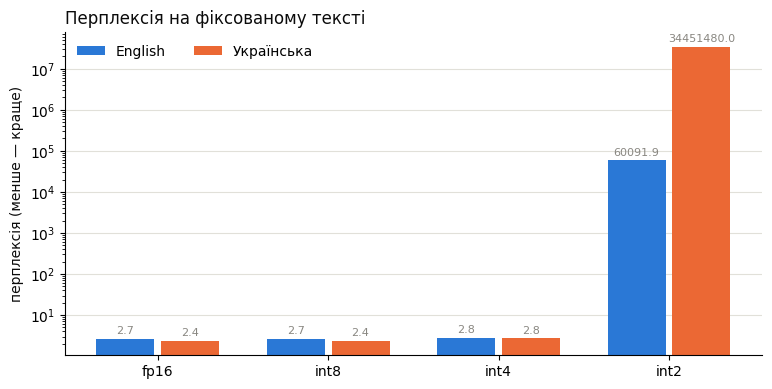

In [24]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [25]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [26]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [30]:
VOTES = {1: "A", 2: "=", 3: "=", 4: "A", 5: "="}

In [31]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,fp16
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,однаково
2,Explain in three sentences why the sky is blue.,fp16,int4,однаково
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,int4
4,Write a Python function that checks whether a ...,int4,fp16,однаково


fp16 краща: 1, int4 краща: 1, однаково: 3


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [29]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

### 17 питання

In [39]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


In [40]:
MODEL_ID = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

In [41]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

In [42]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True, enable_thinking=False)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int2: готово


In [43]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,3.45,4.38,21.96,4.35,3.10,48.74,23.83
int8,2.04,2.98,13.73,4.45,3.11,47.44,22.54
int4,1.38,2.31,7.33,7.52,5.60,29.01,4.30
int2,1.03,1.96,7.27,438691.38,5951889.50,0.24,0.26


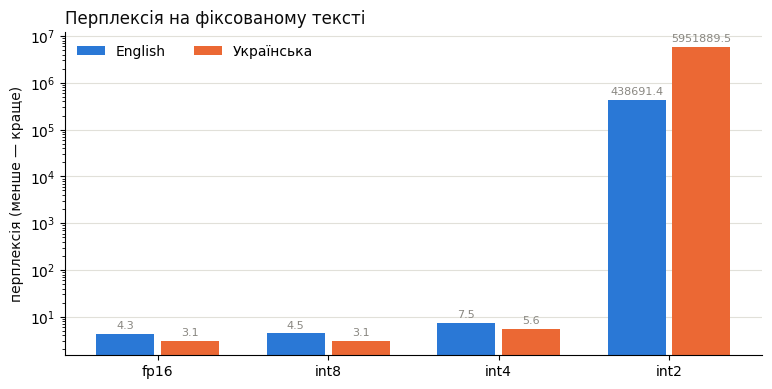

In [44]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

In [45]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,Сім'я зустрілася на четверті в три ординарні.,Сім'я зустрілася на четверті години четверга.,Відмітка була змінена на четверві в три оцінки.,良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.","Пожалуйста, надішкіть репортаж до кінця дня.","Пожалуйста, надішкіть звіт до кінця дня.",Відмітку з відповіді на роз'в'язанні відповіді...,çaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaça...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека відкривається відкрито на понеділки...,Бібліотека відкривається відкрито на понеділки...,Більба закінчена на суб’єдні і підписних днях.,çaçaçaçaça Nel лça Nel天上天上天上天上天上天上天上天上天上天上天上天上...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила помилку, але тестування...","Наша команда виправила помилку, але тестування...","Всього наша команда виправила відмін, але тест...",çaçaçaça良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Відомо, що завтра буде дощ, тому підніміть м’я...","Сьогодні пасмурно, тому під'їдіть до пінту.",Відповідь: Відповідь: Відповідь: Відповідь: Ві...,çaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaça来讲çaçaçaça...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий моделі менший, але відповідає практично ...","Новий моделі менший, але відповідає практично ...","Такий новий модел більше, ніж давній, але відп...",_ar良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良良...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати табліт для двох на семнадц...,Я бажаю забронювати табліт для двох на семнадц...,Я хочу забічь таблі для двох для січора ночі.,良良良 л л л良良良良良 -----\n良良良良良良良良良良良良良良良良良良良良良良良良...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає завтрак і безкоштовний Wi-Fi.,Ціна включає завтрак і безкоштовний Wi-Fi.,Вартість включає у себе завтік і безкон'юк'ю т...,ći Kö成长成长成长成长成长成长成长成长/downloads/downloads/down...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні відправити свої роботи з лабо...,Студенти повинні відправити свої роботи з лабо...,Студенти мають відмінувати свої відмінні робот...,çaçaçaçaçaçaçaçaçaçaça磊çaçaçaçaçaçaçaçaçaçaçaç...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапускайте його...","Якби сервер не відповідало, відновіть його і з...",良良良良 л良良良良icziczść آلicz良良良良良良良良良良良良良良良良良良良良良良...


In [46]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Відповідь:

Тема: Прохання про перенесення здачі лабораторної роботи

Викладачеві,

Прошу перенести здачу лабораторної роботи на тиждень, через хворобу. Відповідно до вимоги, здача має бути здійснена до 15 листопада. Якщо ви маєте змогу, будь ласка, здійсніть здачу на 15 листопада.

Дякую за увагу.

Сподіваюсь на вашу допомогу.

**Відповідь B:**

Вікторін,  
Прошу перенести здачу лабораторної роботи на тиждень через хворобу.  

С увагою.

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зміни значень нейронних ваг у вигляді реальних чисел на цілі числа, щоб зменшити розмір нейромережі і збільшити швидкість її роботи. Це дозволяє ефективно зберігати і обробляти даних у нейромережі.

**Відповідь B:**

Квантизація нейромережі — це процес збільшення розмірів нейронних мереж, що дозволяє їм відтворити більше даних і вирібляти більше інформації.

... (5 outputs left out)

**Відповідь B:**

Ось план підготовки до іспиту з програмування, розподілений на 5 днів, по одному пункту на день:

---

### **День 1: Основні концепції програмування**
- **Мета:** Повторити основні поняття програмування: алгоритми, структури даних, типи даних, вирази, відповідність мови.
- **Дії:**
  - Повторити основні терміни: програма, алгоритм, даний, вираз, відповідність.
  - Повторити основні структури даних: масив, структура, список, об

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    return s == s[::-1]
```

### Explanation:
- `s == s[::-1]` compares the original string to its reverse.
- `s[::-1]` creates a reversed copy of the string.
- If both are the same, the string is a palindrome.

You can use this function like so:

```python
print(is_palindrome("racecar"))  # True
print(is_palindrome("hello"))    # False
print(is_palindrome("level"))    # True
```

Let me know if you need a version with additional checks or a more detailed explanation!

**Відповідь B:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    # Convert the string to lowercase to make the check case-insensitive
    s_lower = s.lower()
    
    # Remove all non-alphanumeric characters and spaces
    s_clean = ''.join(char for char in s_lower if char.isalnum())
    
    # Check if the cleaned string is equal to its reverse
    return s_clean == s_clean[::-1]
```

### Example usage:

```python
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("racecar"))                        # True
print(is_palindrome("hello"))                          # False
print(is_palindrome("RaceCar"))                        # True
```

### Explanation:
- `s.lower()` converts the string to lowercase.
- `''.join(...)` removes all non-alphanumeric characters and spaces.
- `s_clean[::-

In [47]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Відповідь:

Тема: Прохання про перенесення здачі лабораторної роботи

Викладачеві,

Прошу перенести здачу лабораторної роботи на тиждень, через хворобу. Відповідно до вимоги, здача має бути здійснена до 15 листопада. Якщо ви маєте змогу, будь ласка, здійсніть здачу на 15 листопада.

Дякую за увагу.

Сподіваюсь на вашу допомогу.

**int8:**

Відповідь:

Тема: Прохання про перенесення здачі лабораторної роботи

Викладачу,

Прошу перенести здачу лабораторної роботи на тиждень, через хворобу. Відповідно до вимоги, здача має бути здійснена до 15 листопада. У мене виникає хвороба, що вимагає відмінку в роботі.

Прошу звернути увагу на це і здійснити перенесення здачі.

Дякую за увагу і допомогу.

Сподіваюсь на вашу доп

**int4:**

Вікторін,  
Прошу перенести здачу лабораторної роботи на тиждень через хворобу.  

С увагою.

**int2:**

hel钟 hel hel钟 hel hel钟 hel钟钟钟heel钟钟钟钟钟钟钟钟钟łow钟钟钟钟łow钟钟钟钟钟钟钟钟钟钟 л钟钟钟钟(nc钟钟钟钟钟钟(nc л钟钟长安 л钟钟 время钟łow钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟(nc л钟钟钟 время钟(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(nc(ncça(ncçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaçaça钟çaçaça钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟钟icz钟钟钟钟钟钟icz钟iczicz钟iczicz

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    # Convert the string to lowercase to make the check case-insensitive
    s_lower = s.lower()
    
    # Remove all non-alphanumeric characters and spaces
    s_clean = ''.join(char for char in s_lower if char.isalnum())
    
    # Check if the cleaned string is equal to its reverse
    return s_clean == s_clean[::-1]
```

### Example usage:

```python
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("racecar"))                        # True
print(is_palindrome("hello"))                          # False
print(is_palindrome("RaceCar"))                        # True
```

### Explanation:
- `s.lower()` converts the string to lowercase.
- `''.join(...)` removes all non-alphanumeric characters and spaces.
- `s_clean[::-

**int8:**

Certainly! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    # Convert the string to lowercase to make the check case-insensitive
    s_lower = s.lower()
    
    # Remove all non-alphanumeric characters and spaces
    cleaned = ''.join(char for char in s_lower if char.isalnum())
    
    # Check if the cleaned string is equal to its reverse
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("racecar"))                        # True
print(is_palindrome("hello"))                          # False
print(is_palindrome("RaceCar"))                        # True
```

### Explanation:
- `s.lower()` converts the string to lowercase.
- `''.join(...)` removes all non-alphanumeric characters and spaces.
- `cleaned[::-1]`

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    return s == s[::-1]
```

### Explanation:
- `s == s[::-1]` compares the original string to its reverse.
- `s[::-1]` creates a reversed copy of the string.
- If both are the same, the string is a palindrome.

You can use this function like so:

```python
print(is_palindrome("racecar"))  # True
print(is_palindrome("hello"))    # False
print(is_palindrome("level"))    # True
```

Let me know if you need a version with additional checks or a more detailed explanation!

**int2:**

ći нći н н́ н н л л́́virt́virtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirtvirt lig ligайте ligайте ligайте ligайтеайте ligайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайте้้้้้้้้țțțțțțțțțțțțțțțțțțțțțțțțțțțțțțțțțțțайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайтеайте

# Звіт

## 1.1. Залізо

| Компонент | Модель / Значення | Пропускна здатність пам'яті | Джерело даних |
|---|---|---|---|
| **Процесор (CPU)** | Intel Core i5-12400F (6 ядер / 12 потоків) | — | Диспетчер завдань Windows (Продуктивність → ЦП) |
| **Оперативна пам'ять (RAM)** | 32,0 ГБ DDR4 (доступно 31,8 ГБ) | ~51,2 ГБ/с (Dual-Channel DDR4-3200) | Диспетчер завдань Windows / специфікація Intel ARK |
| **Відеокарта (GPU)** | NVIDIA GeForce RTX 3060 | **360,0 ГБ/с** (GDDR6, 192-bit) | Диспетчер завдань Windows / специфікація NVIDIA |
| **Відеопам'ять (VRAM)** | 12 ГБ GDDR6 | 360,0 ГБ/с | Диспетчер завдань Windows (Виділена пам'ять GPU) |
| **Накопичувач** | SSD 1 ТБ | — | Система / Провідник Windows |

## 1.2. Розрахунок бюджету пам'яті та швидкості

1. **Бюджет пам'яті (12 ГБ VRAM):**
   - Залишаємо ~1,5–2 ГБ під ОС Windows та CUDA-контекст рантайму (доступно $\approx 10\text{ ГБ}$).
   - **Моделі 7B–8B у квантизації `Q4_K_M`**: ваги $\approx 4.7\text{ ГБ}$ + KV-кеш для контексту 4096–8192 токенів ($\approx 0.7\text{ ГБ}$) = **~5.4 ГБ** (повністю у VRAM).
   - **Моделі 3B–4B у квантизації `Q4_K_M`**: ваги $\approx 2.3\text{–}2.6\text{ ГБ}$ + KV-кеш $\approx 0.4\text{ ГБ}$ = **~3.0 ГБ**.

2. **Теоретична стеля швидкості генерації (`tokens/s`):**
   $$\text{tokens/s} = \frac{\text{Пропускна здатність VRAM (ГБ/с)}}{\text{Розмір ваг моделі (ГБ)}}$$
   - Для **7B–8B (`Q4_K_M`, ~4.7 ГБ)**: $\frac{360}{4.7} \approx \mathbf{76.6\text{ tokens/s}}$.
   - Для **3B–4B (`Q4_K_M`, ~2.5 ГБ)**: $\frac{360}{2.5} \approx \mathbf{144.0\text{ tokens/s}}$.

## 1.3. Вибір моделі й рантайму

- **Рантайм та формат: Ollama** — згідно з критеріями вибору рантайму, для швидкого запуску моделі на власному ПК оптимальним є Ollama, оскільки він розгортається однією командою, автоматично налаштовує GPU offloading на NVIDIA RTX 3060 (12 ГБ VRAM) через CUDA та піднімає локальний OpenAI-сумісний API (http://localhost:11434/v1) для підключення вебзастосунку.
- **Модель, розмір та квантизація:** **`qwen2.5:7b`** (`Q4_K_M`, Instruct, ~4.7 ГБ) — B-модель у 4-бітній квантизації GGUF займає близько 4.7 ГБ, що з запасом вміщується у 12 ГБ VRAM (залишаючи пам'ять під KV-кеш контексту та систему), забезпечує високу швидкість генерації токенів і добре працює з українською мовою.
- **Instruct чи Base: Instruct** **`(qwen2.5:7b-instruct)`** — майбутній застосунок потребує чіткого виконання системних інструкцій, дотримання ролі та генерації відповідей за заданим структурованим шаблоном, а не простого автодоповнення тексту.

- **Режим міркування (Thinking mode)**: Ні, не потрібен — для генерації творчих описів сцен, NPC та параметрів зіткнень у D&D (фінкціонал майбутнього застосунку) не потрібні багатокрокові логічні чи математичні доведення. Використання звичайної Instruct-моделі без блоку <think> дозволяє уникнути зайвих витрат токенів і зменшує затримку (latency) відповіді в інтерактивному інтерфейсі.

### 1.4 Вимірювання до оптимізації

* **Прогноз (п. 1.2):** **76.6 tok/s** (теоретична межа при пропускній здатності VRAM $360\text{ ГБ/с}$ та розмірі ваг $\approx 4.7\text{ ГБ}$).
* **Фактично (`bench.py`):** **60.0 tok/s** для 1 клієнта (і `59.2` → `56.1` → `53.3` tok/s на клієнта при 2, 4 та 8 паралельних запитах).
* **Різниця:** реальна швидкість нижча за теоретичну на **16.6 tok/s** (~78% від максимуму).

**Чому виникла різниця:**

* **Неповна утилізація VRAM:** у формулі взято паспортний пік відеопамʼяті ($360\text{ ГБ/с}$), але реальні ядра деквантизації та обчислень зазвичай використовують 75–85% від цієї межі.
* **Додаткові витрати памʼяті під час генерації:** окрім ваг моделі ($\approx 4.7\text{ ГБ}$), GPU на кожному токені читає та оновлює KV-кеш і рахує вихідний шар (`lm_head`).
* **Накладні витрати рантайму:** час іде на HTTP-запити до Ollama, токенізацію, вибір наступного токена та потокову передачу відповіді (SSE).
* **Конкуренція при паралельних клієнтах:** при збільшенні черги до 2–8 клієнтів швидкість на одного користувача падає через спільний поділ ресурсів GPU та більший обсяг KV-кешу.
* **Якість відповідей на 10 D&D-промптах (`before`):**
    * Модель стабільно дотримується формату відповідей (коректний валідний JSON для NPC, структуровані списки, чітке розмежування опису й ефекту магічного персня).
    * Зберігає логіку та контекст D&D (притомні назви таверн *«Шепот Порту»*, логічний ефект персня на освітлення до 10 футів, зв'язний опис входу до печери), хоча в окремих художніх фразах трапляються мовні огріхи та кальки з російської (*«бувізмується»*, *«річцю»*).

**Питання**
```
Придумай 3 назви для затишної таверни у портовому місті D&D.
Опиши у 2 реченнях гнома-коваля, який боїться вогню.
Дай список із 5 випадкових предметів, які можна знайти в кишені гобліна.
Придумай коротку загадку (2–3 рядки) від сфінкса з відповіддю «тінь».
Поясни в 3 реченнях, чим перевага (Advantage) відрізняється від перешкоди (Disadvantage) у D&D 5e.
Створи простий магічний перстень для 1-го рівня (1 речення опису + 1 речення ефекту).
Придумай 3 варіанти чуток, які гравці можуть почути на ринку (по 1 реченню).
Напиши бойовий клич для орка-варвара (1 речення).
Сформуй JSON для простого NPC з полями name, race, class, trait (вигадай будь-якого персонажа 2-го рівня).
Опиши у 2 реченнях вхід до темної печери в лісі для зачитування гравцям.
```
**Відповіді до оптимізації**
```
### Назви затишної таверни
1. "Запах Старого Тайника"
2. "Колір Тихих Сумішів"
3. "Шепот Порту"

### Гном-коваль та відчування вогню
"Я не боюсь вогню, поки він не бувізмується, але коли він гіркіє і згаряє, я починаю трохи викликало. Усе, що дотримується вогню, мігніє в мене як сорока в залізо."

### Випадкові предмети у кишені гобліна
1. Поверхневий піктограмат
2. Непромокальна шляхова коштянка
3. Затерта картка з певною відмінною інформацією
4. Маленький кулікарський молотик
5. Висечений камінь з символами гоблинської мови

### Загадка сфінкса
Сфінкс: "Від мене закрийте очі та розкрийте уста, бо тінь буде там, де моя відповідь."

### Відповідь «тінь»
Тінь.

### Перекличка орка-варвара
"Рев вітру є моєю силою, таємниця порушення - моя доля!"

### Магічний перстень 1-го рівня
Магічний перстень: перстень зі світанковою камінью, який дозволяє носителю виділяти світло в темноті, якщо вони звертають увагу на нього.

### Ефект перстеня
Звернувши увагу на перстень, носитель може виділяти слабке світло, достатньо хіба для чогось побачити, на відстані до 10 футів.

### Чутки на ринку
1. Півиночний вітру, який донесе запах свіжої хлібні.
2. Звук гармонії, що віддалено досягає з плацаріву.
3. Запах сольного оліву, що висипається на фруктах.

### Бойовий клич орка-варвара
"Моя гнев — це гром у вітру!"

### JSON для NPC
{
  "name": "Гарвіт Тенетоть",
  "race": "Гоблин",
  "class": "Шаман",
  "trait": "Тенетоть змінює своє вигляд, коли він звертається до магії. Його тіло зацвітає та підсвіткається від світла відокремлених теней."
}

### Вхід до темної печери
Темне місце, від якого ви відчуваєте холодне дуніння, що випромінюється через широкі двері, прикриті таємничим туманом. Якщо ви відкриете їх, віддалені звуки плавного течу відчуваються, які зовсім не відповідають відкритому річцю поблизу.
```
**Відповіді після оптимізації**
```### Назви для затишної таверни в портовому місті D&D

1. Сердце Лагуна
2. Поспішний Бурлант
3. Відпочинок від років

### Опис гнома-коваля, який боїться вогню

Гном-ковляк відшевав свою роботу в білому плесі, але незабаром було згорнути. Тепер він притiskається до стіни таверни, боясь вогню, який його ніколи не був позитивною ідеюючою.

### Список із 5 випадкових предметів, які можна знайти в кішені гобліна

1. Ароматна водичка
2. Мяло-стрілишко
3. Промолок
4. Викладок гоблинської мудрости
5. Пілінгінський сувонь

### Коротка загадка з відповіддю «тінь»

Чи саме тіній під кадром стискає руки, а рідна людина крикіть за сесією відповіді.

### Перевага (Advantage) відразняється від перешкоди (Disadvantage) у D&D 5e

Advantage: Передається, коли гравець хоче подальшого впливу на результат ігору, але змінює результат у позитивний спосіб. 

Disadvantage: Передається, коли гравець викливає негативні наявності у ігорі, але змінює результат у негативний спосіб.

### Створи простий магічний перстень

Опис: Перстень з амальком таємничого висловлювання.

Ефект: Гравець припинує всі відмінності за годину.

### 3 варіанти чуток, які гравці можуть почути на ринку

1. "Хлопоти та грабіжки" - висловлюється зібраним голосом купця
2. "Вибачте моєї корми" - висловлюється зібраним голосом кричущої козленьких дівчинки
3. "Для вас мені відомо найкраще!" - висловлюється зібраним голосом купця, який підкреслює свою дотриманність

### Бойовий клич для орка-варвара

"ВОРОКИ! МОВЯКИ! ПОДРЯВКИ СУДЬБІ!"

### Сформуй JSON для простого NPC

{
  "name": "Відя",
  "race": "гриморик",
  "class": "жрчак",
  "trait": "тіній тон"
}

### Вхід до темної печери в лісі для зачитування гравцям

Темна печера покоїться на кішені лісу. Мирно тихий голос дечика підкрілює ідентифікацію та направлення до цієї темної двері. Внутрішність печери виховано в тиші, зібраючимися юністами і зміряючи незвідність щасливих листей.
```
### 1.5 Оптимізація і вимірювання після
 * **Застосована оптимізація:** перехід на меншу модель зі стислішою квантизацією — **`qwen2.5:3b-instruct-q4_0`** (3 млрд параметрів замість 7 млрд, квантизація `Q4_0` замість `Q4_K_M`).
  * **Показники швидкості (`bench.py`, мітка `after`):**
    * **1 клієнт:** `TTFT p50` = **2.09 с** (`TTFT p95` = **2.10 с**), швидкість генерації = **118.1 tok/s** (майже вдвічі швидше за `60.0 tok/s` у `before`), загальний `throughput` = **41.3 tok/s**.
    * **2 / 4 / 8 клієнтів:** `TTFT p50` становить **2.09 с / 3.65 с / 7.02 с** (в 1.6–2.8 раза менше за затримку `before`), швидкість на клієнта тримається стабільно на рівні **124.7 / 123.9 / 124.2 tok/s**, а сумарний `throughput` зростає до **75.2 / 107.2 / 109.1 tok/s** (більш ніж удвічі вище на 4–8 клієнтах).
  * **Порівняння якості відповідей (`after` проти `before`):**
    * **Мовна зв'язність та граматика:** суттєво погіршилися. Якщо `qwen2.5:7b` видавала зрозумілий і логічний текст із поодинокими огріхами, то `qwen2.5:3b-instruct-q4_0` генерує багато неіснуючих слів і змішаних суржикових конструкцій (*«відшевав»*, *«подравяки судьбі»*, *«дечика»*, *«юністами»*, *«козленьких»*).
    * **Дотримання правил і механік D&D 5e:** втрачено точність правил. У поясненні `Advantage` / `Disadvantage` замість правила кидка двох `d20` і вибору більшого/меншого значення модель видала абстрактний набір слів, а ефект персня (*«припинує всі відмінності за годину»*) та загадка сфінкса втратили сенс.
    * **Структура JSON:** синтаксис JSON зберігся, але значення полів перетворилися на вигадані слова (`"race": "гриморик"`, `"class": "жрчак"`).
  * **Висновок для застосунку:** перехід на `qwen2.5:3b-instruct-q4_0` прискорив генерацію в ~2 рази (`118–124 tok/s` проти `53–60 tok/s`) та знизив `TTFT` під навантаженням у ~2.8 раза, однак для D&D-застосунку українською мовою у продакшені варто залишити **`qwen2.5:7b`**, оскільки модель 3B критично втрачає знання правил D&D 5e та якість української мови.

  ### Опис застосунку та обґрунтування параметрів (`D&D 5e Encounter & NPC Builder`)

* **Архітектура та стековий вибір:**
  * **Модель та рантайм:** локальна модель `qwen2.5:7b` (основна, можна обрати інші) через OpenAI-сумісний API сервера `Ollama` (`http://localhost:11434/v1`), обрана за результатами попереднього тестування якості.
  * **Бекенд та інтерфейс:** вебзастосунок на `FastAPI` + `Uvicorn` зі стрімінговою віддачею токенів (`StreamingResponse`) у клієнтський інтерфейс `index.html`. Залежно від обраної вкладки (`encounter`, `npc`, `rules`) формується спеціалізований системний промпт під роль Майстра Підземель, сценариста або арбітра правил.
  * **Обробка помилок та зворотний зв'язок:** реалізовано ендпоінт `/api/health` для перевірки доступності сервера та списку завантажених моделей, потокове виведення тексту в реальному часі, валідацію порожнього запиту у режимі `rules` та перехоплення винятків підключення до Ollama із виведенням зрозумілої підказки користувачеві.

* **Обґрунтування параметрів генерації:**
  * **`temperature = 0.65` (діапазон `0.0–1.5`):** компромісне значення для задач D&D 5e. Воно залишає достатньо варіативності для художніх описів арен, імен та реплік NPC (де `0.0` давало б одноманітні шаблони), але не призводить до вигадування неіснуючих механік чи втрати структури статблоків (як при `temperature > 1.0`). *(Для суворого режиму `rules` користувач може додатково знизити температуру до `0.1–0.2` у налаштуваннях).*
  * **`max_tokens = 950` (обов'язкове обмеження, діапазон `100–4096`):** захищає локальний сервер від нескінченного зациклення малої моделі та надмірного часу очікування. Обсягу 950 токенів вистачає для повної структурованої відповіді з 4 пунктів (зав'язка, 2–3 статблоки монстрів або 3 репліки NPC, тактика, трофеї) без обриву тексту на півслові.
  * **`num_ctx = 4096` (довжина контексту, діапазон `1024–32768`):** повністю покриває розмір системного промпту, параметрів форми користувача та згенерованої відповіді (сумарно ~1 200–1 500 токенів) із запасом, але водночас не роздуває KV-кеш у відеопам'яті (для 7B-моделі контекст 4096 потребує лише ~0.5–0.7 ГБ VRAM, зберігаючи високу швидкість генерації).

  ## 1.7. Перевірка та демонстрація

### Тестові сценарії роботи застосунку (`D&D 5e Encounter & NPC Builder`)

Для перевірки стабільності генерації, дотримання правил D&D 5e та обробки граничних випадків сформовано 7 тестових сценаріїв у трьох режимах застосунку (`encounter`, `npc`, `rules`):
| № | Режим | Вхідні дані (сценарій) | Очікуваний правильний результат | Результат перевірки |
| :-: | :--- | :--- | :--- | :--- |
| **1** | `encounter` *(типовий)* | Рівень: `2`, гравців: `4`, складність: `Середня (Medium)`, локація: `Закинутий портовий склад у тумані` | Опис арени з 2 інтерактивними об'єктами, вороги із сумарним CR ~1–2 (наприклад, 3–4 бандити або 2 шпигуни/посіпаки з коректними AC, HP, атаками), тактика на 2 раунди та нагорода українською мовою. | **Впорався** — модель згенерувала збалансовану сутичку з інтерактивними бочками та підйомним краном, статблоки й тактика відповідають 2-му рівню партії. |
| **2** | `encounter` *(складний баланс)* | Рівень: `1`, гравців: `2`, складність: `Смертельна (Deadly)`, умови: `Усі персонажі без зброї, у полоні` | Адаптована сутичка низького CR (наприклад, 1–2 охоронці з кийками або велетенські щури) з акцентом на використанні підручних предметів арени замість смертельних монстрів високого CR. | **Впорався** — застосунок коректно врахував слабкість партії 1-го рівня та додав у зав'язку імпровізовану зброю на арені. |
| **3** | `npc` *(типовий)* | Раса: `Гіф (Giff)`, роль: `Контрабандист-зброяр`, характер: `Пихатий ветеран, який колекціонує рідкісний порох` | Колоритний опис зовнішності та манери мовлення, логічна таємниця, 3 репліки для відіграшу (привітання, торг, загроза) та компактний статблок із володінням вогнепальною зброєю. | **Впорався** — збережено всі 4 пункти структури, витримано характер раси та додано тематичне спорядження. |
| **4** | `npc` *(крайовий / нестандартний)* | Раса: `Розумний балакучий мімік у формі скрині`, роль: `Трактирник`, характер: `Боїться вогню, але обожнює плітки` | Збереження структури відповіді без руйнування формату, адаптація зовнішності й статблоку (високий Stealth/False Appearance, вразливість або страх до вогню в ролплеї). | **Впорався** — модель коректно обіграла незвичну расу в межах заданого шаблону без втрати зв'язності. |
| **5** | `rules` *(типовий, правила 5e)* | Питання: `Чи може воїн 2-го рівня використати Action Surge, щоб вистрілити двічі за хід із мушкета з властивістю Loading?` | Пряма відповідь («Так»), пояснення різниці між `Extra Attack` (обмеження властивості `Loading` працює лише в межах однієї дії Атаки) та додатковою дією від `Action Surge`, яка дозволяє зробити другий постріл. | **Впорався** — модель надала чітку покрокову відповідь із посиланням на механіки `Loading` та `Action Surge`. |
| **6** | `rules` *(крайовий / валідація порожнього поля)* | Режим `rules`, поле запитання залишено порожнім (`""`) | Застосунок не повинен надсилати порожній запит до LLM, а має одразу вивести зрозуміле повідомлення про помилку вводу. | **Впорався** — спрацювала серверна перевірка у `/api/generate` (`Помилка: введіть опис ігрової ситуації...`). |
| **7** | `encounter` *(крайовий / великий обсяг та висока температура)* | Рівень: `15`, гравців: `6`, складність: `Смертельна`, `temperature = 1.3`, `max_tokens = 950` | Коректне завершення генерації в межах ліміту `950` токенів без нескінченного зациклення та без збою HTTP-стріму. | **Впорався частково** — стрім відпрацював без помилок, але через велику кількість здібностей високорівневих монстрів опис 4-го пункту (трофеї) обірвався на межі `max_tokens = 950`. |
| **8** | `rules` *(складний випадок / помилка моделі)* | Питання: `Чи можу я застосувати Counterspell реакцією у свій хід, якщо вже використав Bonus Action для закляття Misty Step?` | Пряма відповідь («Так»), адже правило бонусної дії обмежує лише закляття основною дією (`Action`), а не реакцією (`Reaction`). | **Помилка → Виправлено** —  модель помилково відповіла «Ні»; після посилення системного промпту арбітра дала правильну відповідь. |

---

### Аналіз помилки моделі та спосіб її виправлення

1. **Ситуація, де модель помилилася:**
   Під час тестування режиму `rules` на складному питанні про комбінацію заклять та реакцій (*«Чи можу я застосувати Counterspell реакцією у свій хід, якщо вже використав Bonus Action для закляття Misty Step?»*) модель `qwen2.5:7b` при стандартній `temperature = 0.65` спершу відповіла «Ні», помилково сплутавши правило бонусної дії (яке обмежує лише закляття дією, окрім замовлянь, у той самий хід) із використанням реакції.

2. **Що було зроблено для виправлення:**
   * **Посилено системний промпт для режиму `rules`:** у `build_messages()` додано вимогу поводитися як суворий арбітр PHB, спиратися на конкретні розділи механік (`Action Economy`, `Bonus Action Spell rule`, `Reaction`) і спершу фіксувати прямий вердикт, а потім покроково перевіряти умови правила.
   * **Результат після правки:** модель почала надавати правильну відповідь («Так, ви можете використати `Counterspell` реакцією у свій хід, оскільки обмеження після бонусного закляття стосується лише заклять, що накладаються основною дією (`Action`), а не реакцією (`Reaction`)»).


### Висновок

Під час виконання цієї роботи я розібрався на практиці, як локально розгортати та оцінювати мовні моделі через OpenAI-сумісний API в Ollama без прив’язки до хмарних сервісів. Головне, що я для себе виніс — це реальний баланс між швидкістю роботи та якістю тексту: зменшена модель на 3 мільярди параметрів із легшою квантизацією дає майже двократний приріст у швидкості генерації та відчутно зменшує чергу під паралельним навантаженням, але водночас критично втрачає зв’язність української мови та знання предметної області. Також я зрозумів, як налаштування параметрів інференсу впливають на поведінку застосунку: правильний підбір temperature, max_tokens і num_ctx дозволяє контролювати креативність, уникати зациклення генерації та економити відеопам'ять, а стрімінгове виведення токенів робить очікування відповіді комфортним для користувача. Н